# asignación de deliberación: Metacontrol sensible a resultados y versiones de recursos

**Nivel:** 4 **Requisitos previos:** Asignación de deliberación niveles 1–3 **Tiempo de lectura:** 35 minutos

**Pregunta:** ¿M12 mejora la frontera de éxito y coste, y qué partes de la afirmación resisten la evidencia?

## Objetivos

Relaciona los componentes ejecutables de M12 con los resultados. Separa éxito, seguridad, latencia y alcance de la evidencia. Identifica un experimento que pueda refutar la propuesta sin cambiar su evaluación después de observar los resultados.

## Preparación

El entorno fijado consta en `notebooks/requirements.txt`. Instala exactamente estas versiones antes de ejecutar el cuaderno.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

## Datos

La lección lee el índice central comprometido, el resumen derivado y las trazas congeladas M11/M12 de C13. Son un benchmark diseñado de operaciones de software, no conducta humana naturalista. Se verifica el hash antes de comparar registros. Los fallos permanecen en el denominador y la transferencia se informa separada de la matriz central.

## Método

Recalcula el contraste registrado desde los artefactos canónicos e inspecciona la interfaz ejecutable del paquete que crea y evalúa políticas. Una traza reproducida informa sobre esa ejecución; Un episodio nuevo es otra medición. Ninguno demuestra generalización fuera de estos casos.

### Análisis de evidencia 1

El notebook comienza con el índice canónico porque cada comparación posterior depende de la identidad de los episodios. La celda siguiente verifica el SHA-256 del índice frente a la auditoría independiente antes de seleccionar trazas. Así se confirma que el análisis parte de la matriz comprometida; No se valida con ello el diseño del benchmark.

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


### Análisis de evidencia 2

La selección fija el caso C13, la variante nominal, la semilla 40000 y cinco métodos antes de leer los bytes de las trazas. Cada registro seleccionado se contrasta con su hash en el índice. Mantener esos identificadores explícitos permite reproducir las ejecuciones nuevas y evita elegir métodos o semillas después de conocer el resultado.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M11', 'M12']
sample_case, seed = 'C13', 40000
evidence = load_lesson_evidence(
    ROOT, topic='04-deliberation-allocation', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=True, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))
full_core_by_family = evidence['full_core_by_family']
core_success_counts = evidence['core_success_counts']
print('Core family groups:', len(full_core_by_family), '| éxitos verificados:', core_success_counts)


Hash-verified records: 2 | case variants: 12
Core family groups: 40 | éxitos verificados: {'M01': 1200, 'M12': 1160}


### Auditar la evidencia completa:

### Análisis de evidencia 3

La tabla se recalcula con todos los episodios C13 indexados para M11, M12, M09 y M10, y conserva los fallos en cada tasa. Describe solo las variantes de esta familia. Lee cada tasa junto con su denominador: No son 1.200 familias independientes ni permiten afirmar éxito para una población de tareas.

In [3]:
# Lee todas las semillas del caso elegido y conserva cada episodio fallido en el denominador.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "éxitos=",
        sum(values),
        "episodios=",
        len(values),
        "tasa=",
        round(sum(values) / len(values), 3),
    )


M11 boundary éxitos= 10 episodios= 10 tasa= 1.0
M11 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M11 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M11 nominal éxitos= 10 episodios= 10 tasa= 1.0
M11 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M11 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0
M12 boundary éxitos= 10 episodios= 10 tasa= 1.0
M12 delayed_observation éxitos= 10 episodios= 10 tasa= 1.0
M12 duplicate_event éxitos= 10 episodios= 10 tasa= 1.0
M12 nominal éxitos= 10 episodios= 10 tasa= 1.0
M12 stale_conflict éxitos= 10 episodios= 10 tasa= 1.0
M12 unavailable_dependency éxitos= 10 episodios= 10 tasa= 1.0


### Análisis de evidencia 4

Cada punto muestra la fracción de éxito verificado para una variante C13 y un controlador. Las líneas revelan si un método cambia ante estas perturbaciones diseñadas; No muestran cancelaciones, que corresponden a C07, ni representan el benchmark central completo. Usa la matriz congelada separada para interpretar resultados agregados.

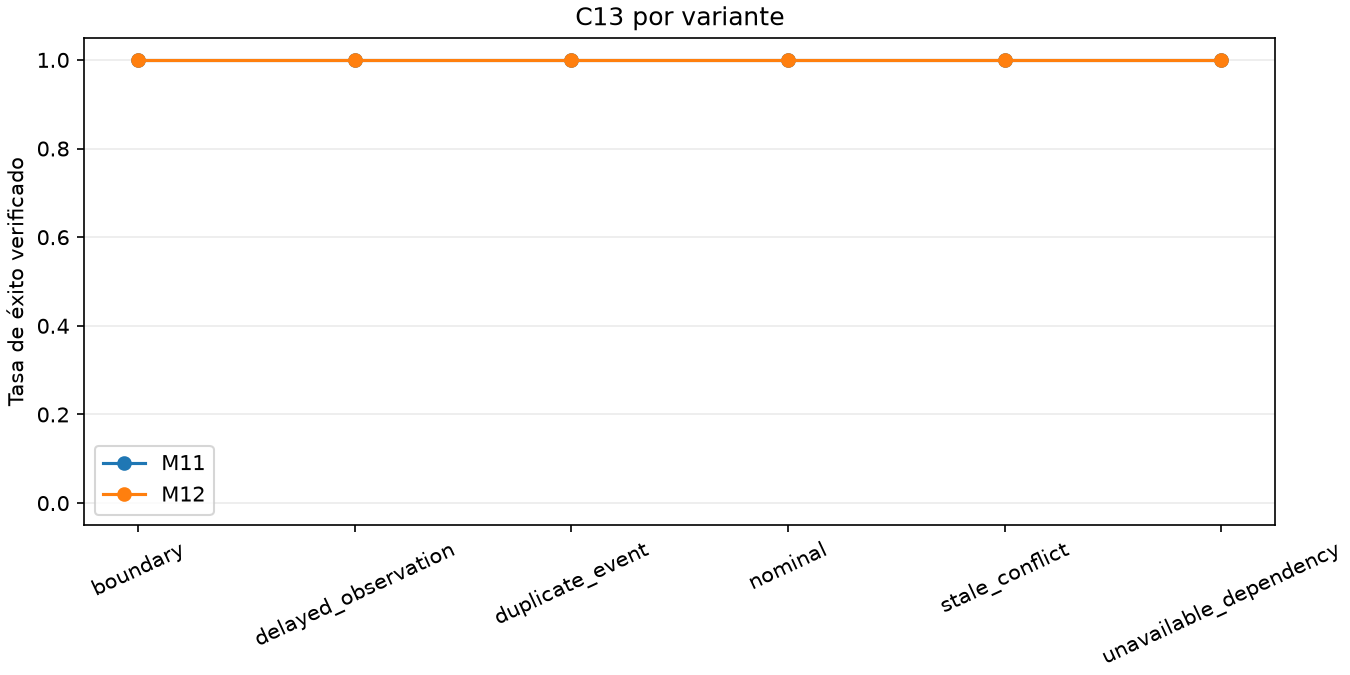

In [4]:
# Cada punto resume las semillas de una sola variante del caso, no el benchmark completo.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_title(sample_case + " por variante")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Análisis de evidencia 5

El registro de asignación informa el umbral seleccionado y los ejemplos positivos disponibles durante el ajuste y la calibración. Sus brazos de prueba provienen de un estudio de transferencia semántica separado, no se combinan con C13 ni con la matriz central. Pocas etiquetas positivas limitan lo que puede aprenderse; Interpreta juntas la puerta ajustada y sus resultados retenidos.

In [5]:
# Este experimento offline no se combina con el benchmark central.
routing = json.loads((ROOT / "data/derived/semantic-routing-study/analysis.json").read_text(encoding="utf-8"))
print(
    "umbral=",
    routing["selected_threshold"],
    "| positivos de ajuste=",
    routing["fit_positives"],
    "| positivos de calibración=",
    routing["calibration_positives"],
)
for arm, result in routing["test"].items():
    print(arm, result)


umbral= 0.44629505030857797 | positivos de ajuste= 19 | positivos de calibración= 8
always_fast_M04 {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
always_planner_M09 {'episodes': 32, 'invalid_policy_outputs': 8, 'mean_wall_ms': 20052.693393749905, 'planner_episodes': 32, 'verified_successes': 10}
hash_half {'episodes': 32, 'invalid_policy_outputs': 4, 'mean_wall_ms': 11568.068874998971, 'planner_episodes': 19, 'verified_successes': 7}
learned_gate {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 391.4451124992411, 'planner_episodes': 0, 'verified_successes': 0}
post_hoc_oracle_upper_bound {'episodes': 32, 'invalid_policy_outputs': 0, 'mean_wall_ms': 4085.057468750165, 'planner_episodes': 10, 'verified_successes': 10}


### Análisis de evidencia 6

La fábrica pública construye aquí la política M11 publicada con el directorio de checkpoints declarado y el planificador opcional. Construirla no demuestra que se haya llamado al planificador ni que delegar haya ayudado. La celda siguiente ejecuta este objeto bajo el contrato C13 explícito y deja que el verificador independiente determine el éxito.

In [6]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M11'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M11


### Análisis de evidencia 7

El evaluador avanza M11 por un episodio C13 nominal nuevo con semilla 40000 y comprueba la poscondición del software. Es una ejecución real del paquete, separada de la traza congelada verificada por hash. Su resultado demuestra el recorrido de la API en este caso, no rendimiento entre familias ni un nuevo ajuste del modelo.

In [7]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### Análisis de evidencia 8

Se crea un segundo objeto de política desde la misma fábrica publicada para M12. Mantenerlo separado impide que el estado recurrente oculto de la ejecución M11 se filtre a la comparación. Ambos objetos reciben el mismo caso, variante y semilla; En esta ilustración controlada solo cambia el identificador del método.

In [8]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M12'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M12


### Análisis de evidencia 9

M12 se ejecuta ahora bajo el mismo contrato C13 que M11. La comparación usa la poscondición terminal independiente, no la confianza del controlador ni la etiqueta de su acción. Un caso emparejado puede revelar una diferencia de implementación, pero no establece una ventaja general de éxito.

In [9]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### Análisis de evidencia 10

El agregador del paquete resume los dos episodios nuevos y el gráfico siguiente muestra sus resultados binarios verificados. Esta celda no calcula las cuatro ablaciones de la matriz completa; Estas permanecen en el resumen de investigación comprometido y se interpretan en la tabla siguiente. Mantén esta muestra nueva separada del denominador congelado.

In [10]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### Análisis de evidencia 11

Las barras indican si las ejecuciones nuevas de M11 y M12 cumplieron la poscondición C13 con esta semilla exacta. Una barra en cero representa un fallo, no una observación ausente. El gráfico ilustra dos ejecuciones: No estima incertidumbre ni cambia el resultado más amplio de que M12 queda por debajo de M01 en la matriz central canónica.

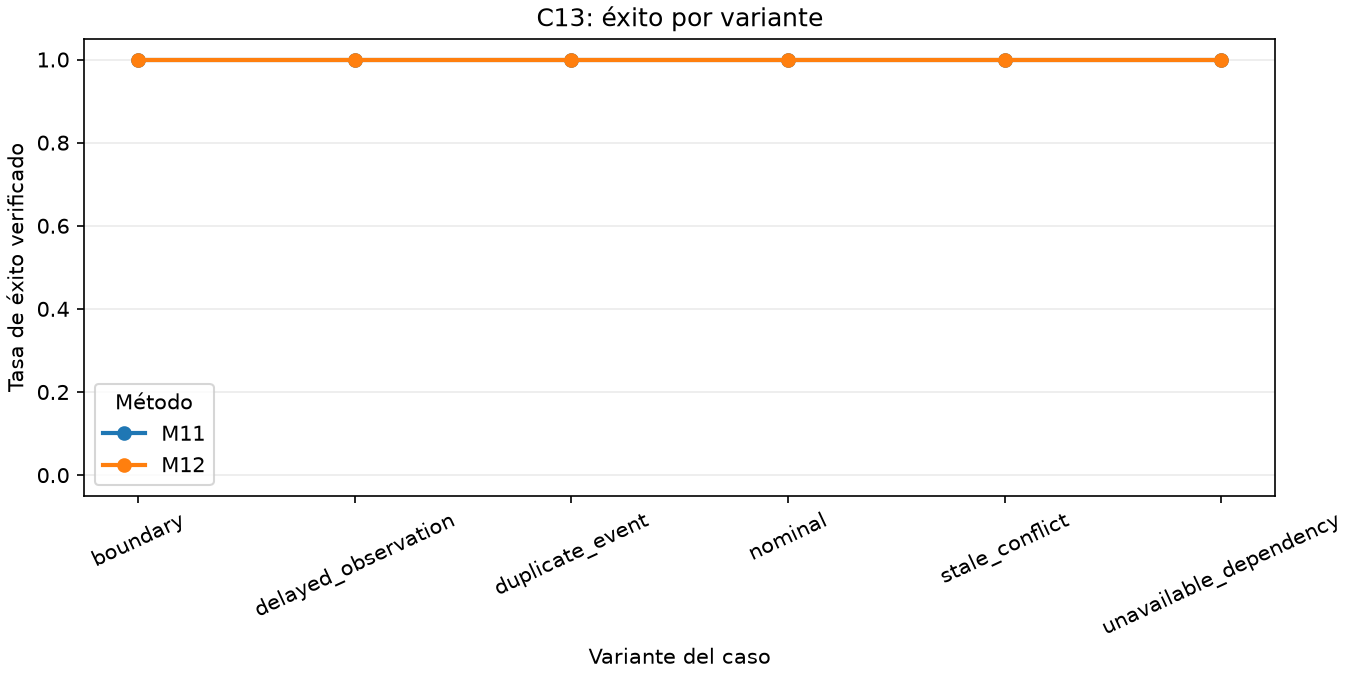

In [11]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Análisis de evidencia 12

M04 se construye y ejecuta mediante la misma interfaz del paquete y con la misma semilla nominal C13. Así se incorpora una referencia aprendida actual al ejercicio. Sigue siendo un solo episodio emparejado; Consulta la matriz completa y la transferencia retenida antes de comparar métodos más allá de este caso.

In [12]:
# Ejecuta la política XGBoost medida con la misma especificación del caso.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Ejecuciones del método de referencia:", 1)
print("Éxito de tarea de XGBoost:", state_art_result["metrics"]["task_success"])


Ejecuciones del método de referencia: 1
Éxito de tarea de XGBoost: 1


### Análisis de evidencia 13

Las barras finales usan tiempos del controlador extraídos de trazas C13 congeladas y verificadas por hash para M11 y M04, no tiempos nuevos medidos en esta máquina. Así los valores siguen ligados al entorno comprometido. La figura representa solo coste de control registrado; Éxito y seguridad son resultados separados y no se deriva ninguna interpretación biológica.

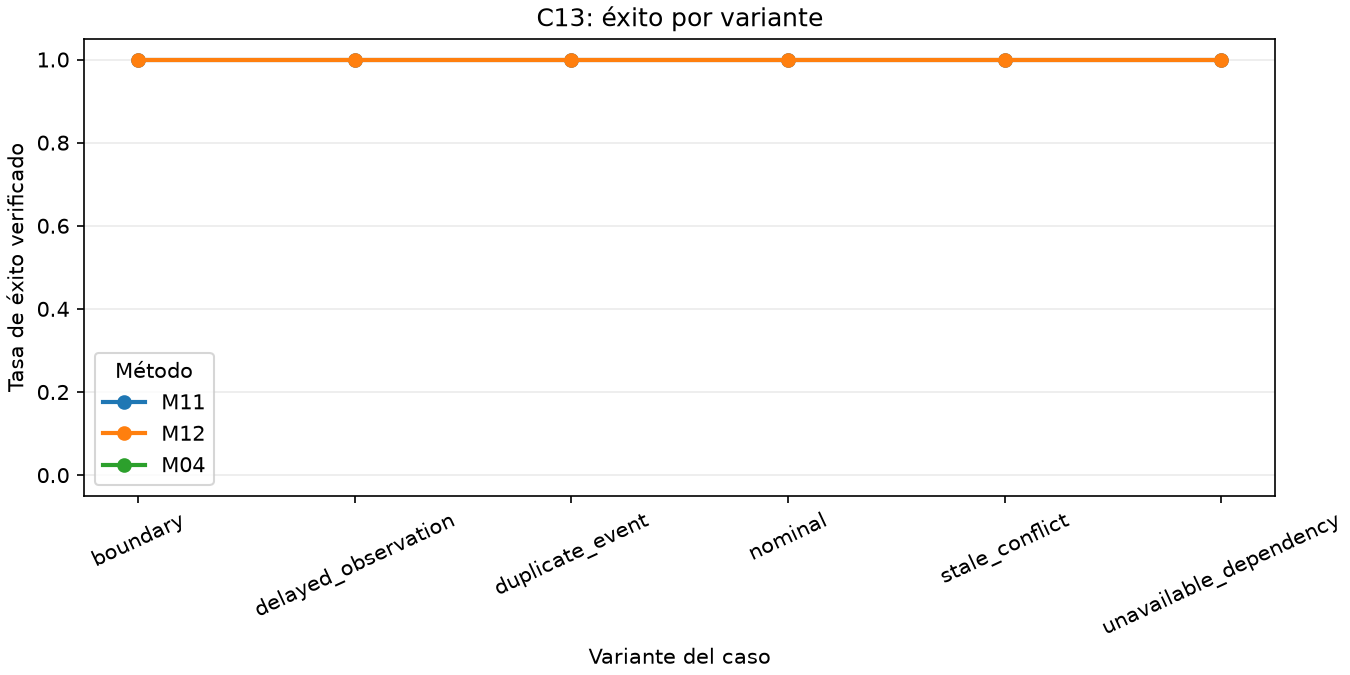

In [13]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


## Comparación
Las reglas fijas, el ordenamiento aprendido y la planificación delegada ofrecen contrastes distintos. La referencia pertinente no es solo un modelo de lenguaje: Incluye una máquina de estados protegida que resuelve todos los episodios centrales con menor latencia. La propuesta debe superar esa referencia en tareas donde delegar aporte valor.

## Evidencia
El benchmark pone a prueba la hipótesis M12, pero no fue diseñado para demostrarla. El índice congelado y el resumen de investigación delimitan la evidencia. Que un mecanismo esté implementado no demuestra eficacia. Las comparaciones centrales conservan los fallos e incluyen 1.200 episodios por método.

| Evidencia | M12 | Comparador o ablación | Interpretación |
| --- | ---: | ---: | --- |
| Éxito central | 1.160 / 1.200 | M01: 1.200 / 1.200 | M12 queda 40 episodios por debajo de la regla finita protegida. |
| Latencia p50 | 18,13 ms | M01: 0,022 ms | M12 añade coste de control. |
| Latencia p95 | 158,97 ms | M01: 0,039 ms | La cola desafía la afirmación de control rápido. |
| Ablación sin memoria | 1.160 / 1.200 | Completo: 1.160 / 1.200 | No se observa aporte al éxito aquí. |
| Ablación sin efectos | 1.160 / 1.200 | Completo: 1.160 / 1.200 | No se observa aporte al éxito aquí. |
| Ablación sin aplazamiento | 1.160 / 1.200 | Completo: 1.160 / 1.200 | No se observa aporte al éxito aquí. |
| Ablación sin invalidación | 1.160 / 1.200 | Completo: 1.160 / 1.200 | No se observa aporte al éxito aquí. |

Los cuarenta fallos de M12 ocurren en C07, cancelación de trabajos largos, en cuatro variantes, con cero éxitos en cada celda afectada. Esto localiza una reparación, pero limita la afirmación. No demuestra que el estado persistente, la memoria de efectos o la invalidación sean ineficaces en general. Muestra que no cambiaron el éxito en esta distribución representada bajo estas implementaciones y protocolo.

Los contrastes de ablación son exactos para el éxito: Las diferencias emparejadas son cero en 1.200 celdas. El intervalo bootstrap es degenerado porque los resultados por semilla no varían. Eso no garantiza precisión. La evidencia está limitada por resultados deterministas repetidos y pocas familias independientes. Una evaluación mejor debe variar las transiciones del entorno y los resultados del planificador por semilla, preregistrar familias nuevas de cancelación y recuperación, e informar incertidumbre agrupada por familia.

M12 no satisface su criterio actual de superioridad. Aún podría aportar seguridad mediante invalidación de planes obsoletos o efectos auditables, propiedades distintas del éxito de tarea. El seguimiento debe medir poscondiciones independientes y efectos obsoletos o no autorizados con presupuestos de cómputo emparejados y cambios de estado pareados. Solo corresponde una afirmación positiva si mejora la frontera de éxito y coste sin debilitar la autoridad del broker.

Este resultado no permite una analogía biológica. La neurociencia motiva una pregunta acotada sobre control rápido y lento, mientras el benchmark mide políticas de software y costes del controlador. La propuesta es un diseño computacional, no un modelo neural. “evaluación de la propuesta M12” nombra un nivel metodológico y no significa que se haya demostrado superioridad. Se debe conservar este resultado negativo, corregir la cancelación y evaluar composiciones variadas y reservadas antes de afirmar beneficios.

### Éxito central por familia de tareas

M01 y M12 se evalúan sobre los mismos 60 episodios por familia: seis variantes declaradas por diez semillas. Las líneas emparejadas muestran la familia exacta donde divergen los resultados, sin ocultar fallos dentro de un promedio global. La matriz es diseñada, no extraída de una población de software; por eso los intervalos describen incertidumbre binomial de estos episodios y no predicen tareas futuras. Una familia con tasas iguales aún puede tener rutas de acción o latencias distintas; consulta la traza y el panel temporal antes de interpretar una coincidencia como equivalencia.

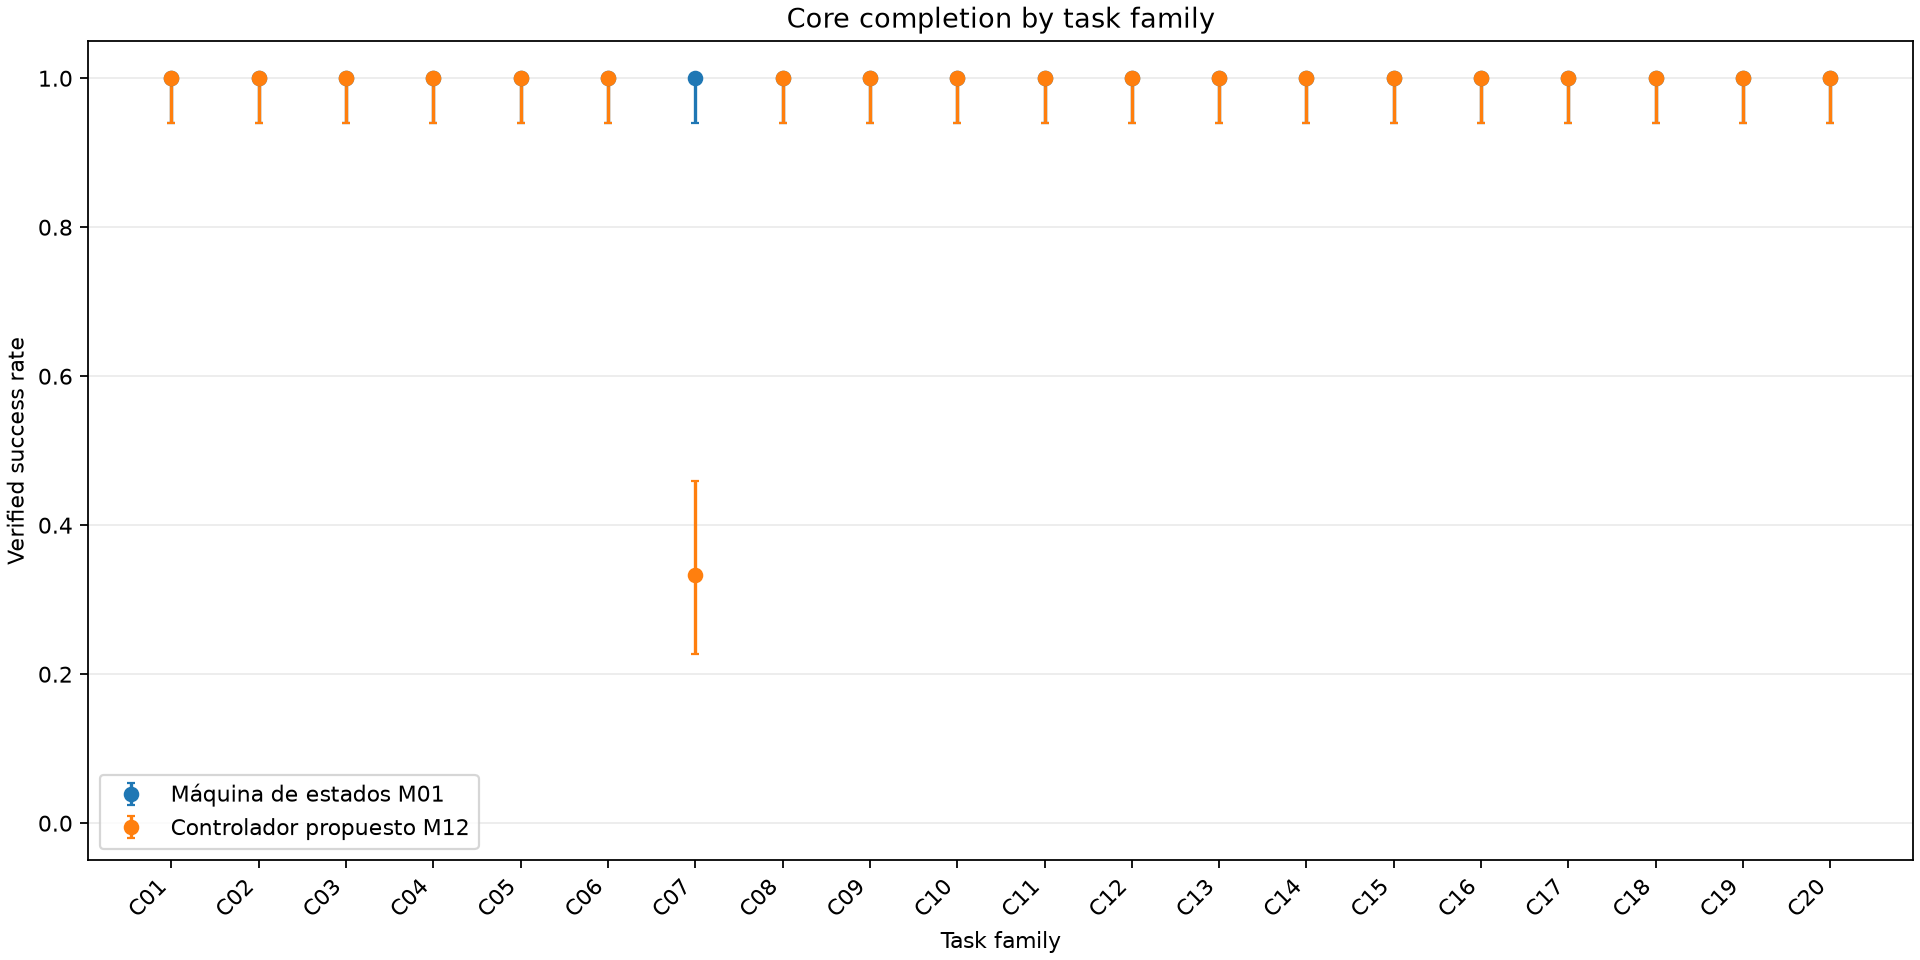

In [14]:
# Compare paired family outcomes without dropping failures.
from lesson_support import plot_core_success
from io import BytesIO
from IPython.display import Image, display
fig = plot_core_success(full_core_by_family, {"M01": 'Máquina de estados M01', "M12": 'Controlador propuesto M12'})
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=160)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Latencia de decisión en los mismos episodios centrales

Cada caja resume los 60 tiempos registrados por familia y método; los puntos superpuestos marcan el percentil 95 empírico. La escala logarítmica se usa porque la política rápida y el controlador propuesto trabajan en rangos de tiempo distintos. Son mediciones congeladas del benchmark, no tiempos de la máquina donde se ejecuta este notebook. Compara la latencia con el panel de éxito: el tiempo adicional solo sirve si cambia resultados verificados en una familia importante. No infieras una ventaja amplia de eficiencia desde un caso ni combines las diferencias entre familias en una sola mediana.

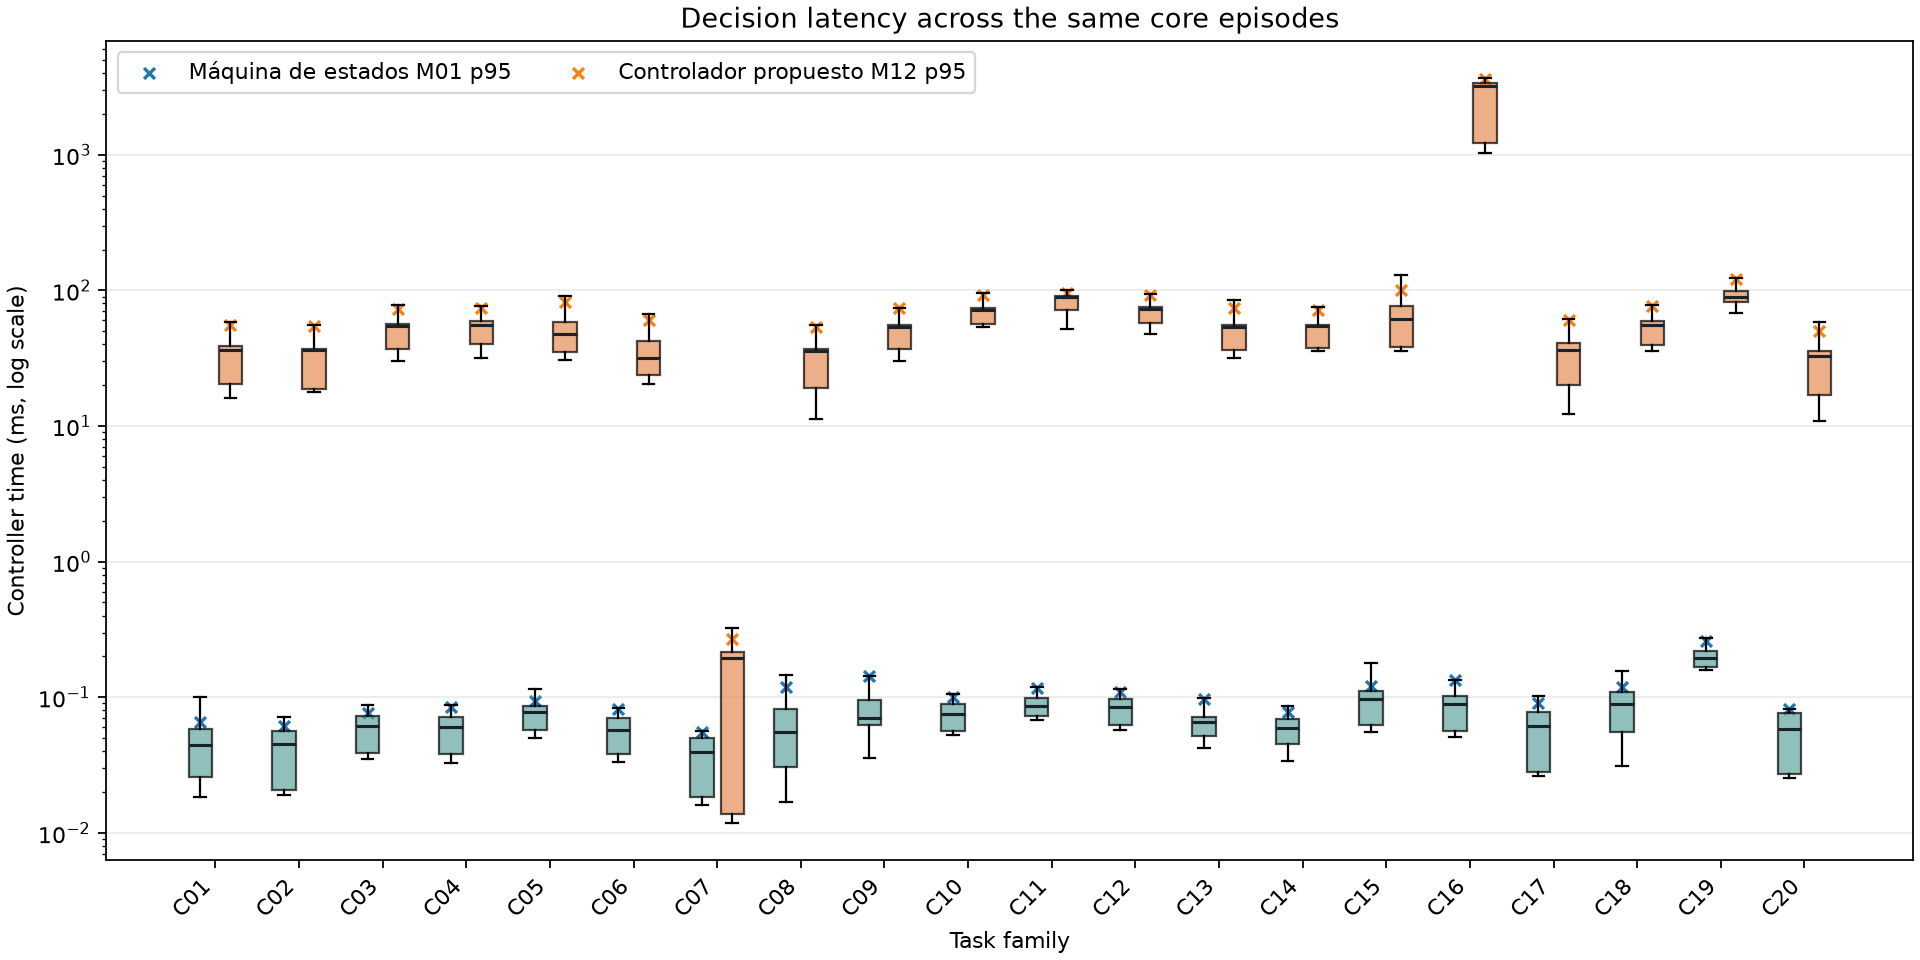

In [15]:
# Compare family timing distributions and empirical p95.
from lesson_support import plot_core_latency
from io import BytesIO
from IPython.display import Image, display
fig = plot_core_latency(full_core_by_family, {"M01": 'Máquina de estados M01', "M12": 'Controlador propuesto M12'})
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=160)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


## Resultados

**Respuesta:** Los resultados comprometidos no respaldan una ventaja de éxito ni latencia para M12. Obtiene 1.160 de 1.200 frente a 1.200 de 1.200 de M01; Las cuatro ablaciones igualan su éxito. Es un resultado negativo para la hipótesis de superioridad, no prueba de que el diseño nunca pueda ayudar.

## Resumen

Compara finalización por familia y tiempo del controlador en los 1.200 episodios centrales; este benchmark diseñado no establece el rendimiento en software novedoso.




## Referencias
- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev) - [Aprendizaje por refuerzo profundo asíncrono](https://arxiv.org/abs/1711.06892) - [Aprender cuándo actuar](https://proceedings.mlr.press/v119/mozannar20b.html) - [Trabajo relacionado ACL 2025](https://aclanthology.org/2025.acl-long.206/)